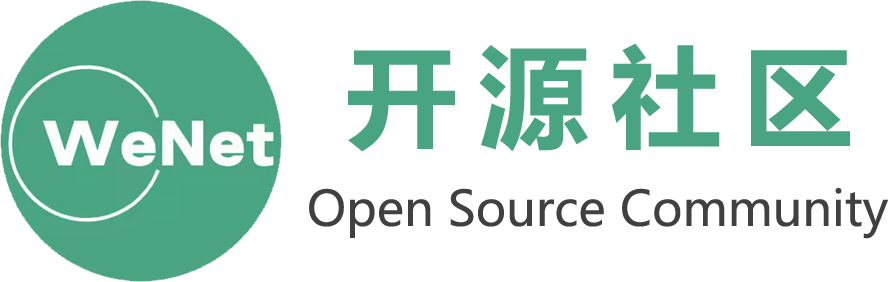

# WeNet ASR and Word Error Rate (WER) Evaluation

This notebook performs automatic speech recognition (ASR) using the English WeNet model and evaluates the recognized transcripts against the reference transcripts using Word Error Rate (WER).

The workflow is organized into configuration, model setup, audio inference, text normalization, WER calculation, and result export. It is intended to be run from the root of the project repository.

## Evaluation dataset

The original evaluation protocol uses 400 TIMIT utterances:

- 200 female utterances: 20 speakers × 10 utterances
- 200 male utterances: 20 speakers × 10 utterances

The audio files are processed in this order: female speakers (`F_1_1` through `F_20_10`), followed by male speakers (`M_1_1` through `M_20_10`). The reference transcript file must follow the same order.

## Metric

WER is calculated as:

\[
\mathrm{WER} = \frac{S + D + I}{N}
\]

where *S* is the number of substitutions, *D* is the number of deletions, *I* is the number of insertions, and *N* is the number of words in the reference transcript.

**Lower WER indicates better ASR performance.** The notebook reports corpus-level WER as the primary result, preserving the aggregate evaluation approach used in the original notebook. When the reference file contains exactly one non-empty line per utterance (400 lines), utterance-level WER is also calculated.

## 1. Install dependencies

Run the installation cells in an environment with internet access. The WeNet package is installed from its GitHub repository, as in the original implementation.

`torch_npu` is not installed because it is intended for Huawei Ascend NPU environments and is not required for a standard CPU or NVIDIA GPU setup.

In [ ]:
%pip install --upgrade pip
%pip install git+https://github.com/wenet-e2e/wenet.git
%pip install jiwer soundfile numpy pandas

## 2. Imports and configuration

Update the paths and filename pattern below to match the directory layout of your repository.

The default filename pattern matches the example in the original notebook:
`F_1_1_BF_LinearSuperDirective_17mics_weighted_RT1(s)_SNR_10dB_regul1_R0.1m.wav`.

If you evaluate another processing condition, change `SCENARIO_SUFFIX`; the rest of the notebook can remain unchanged.

In [ ]:
from pathlib import Path
import re
import string
import time
import warnings

import numpy as np
import pandas as pd
import soundfile as sf
from jiwer import wer

# Project root: this notebook is expected to be launched from the repository root.
PROJECT_ROOT = Path.cwd()

# Directory containing the audio files for the selected evaluation condition.
AUDIO_DIR = PROJECT_ROOT / "data" / "enhanced"

# Text file containing the 400 reference transcripts, in the required order.
REFERENCE_FILE = PROJECT_ROOT / "data" / "ground_truth" / "Ground_Truth_text_1.txt"

# Results directory.
RESULTS_DIR = (
    PROJECT_ROOT / "results" / "evaluation" / "speech_quality" / "WER"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Dataset configuration.
NUM_SPEAKERS = 20
NUM_UTTERANCES = 10
SPEAKER_TYPES = ["F", "M"]

# Replace this suffix when evaluating another scenario.
SCENARIO_SUFFIX = (
    "BF_LinearSuperDirective_17mics_weighted_RT1(s)_SNR_10dB_regul1_R0.1m"
)

# Example: F_1_1_<SCENARIO_SUFFIX>.wav and M_1_1_<SCENARIO_SUFFIX>.wav
AUDIO_FILENAME_PATTERN = "{speaker}_{speaker_id}_{utterance_id}_" + SCENARIO_SUFFIX + ".wav"

# WeNet model identifier used in the original notebook.
WENET_MODEL_NAME = "english"

print("Project root:", PROJECT_ROOT)
print("Audio directory:", AUDIO_DIR)
print("Reference file:", REFERENCE_FILE)
print("Results directory:", RESULTS_DIR)

## 3. Load the WeNet model

The English pretrained model is loaded using `wenet.load_model('english')`, matching the original notebook. The first run may download model files and can take some time.

For reproducibility, record the WeNet package version and the model identifier with the experiment.

In [ ]:
import wenet

model = wenet.load_model(WENET_MODEL_NAME)
print(f"WeNet model loaded: {WENET_MODEL_NAME}")

## 4. Build the evaluation file list

The file list is generated in the same order as the original evaluation: all female utterances first, followed by all male utterances. Missing audio files are reported before inference starts.

In [ ]:
evaluation_items = []

for speaker_type in SPEAKER_TYPES:
    for speaker_id in range(1, NUM_SPEAKERS + 1):
        for utterance_id in range(1, NUM_UTTERANCES + 1):
            filename = AUDIO_FILENAME_PATTERN.format(
                speaker=speaker_type,
                speaker_id=speaker_id,
                utterance_id=utterance_id,
            )
            evaluation_items.append({
                "speaker_type": speaker_type,
                "speaker_id": speaker_id,
                "utterance_id": utterance_id,
                "audio_filename": filename,
                "audio_path": AUDIO_DIR / filename,
            })

missing_files = [
    str(item["audio_path"])
    for item in evaluation_items
    if not item["audio_path"].is_file()
]

if missing_files:
    preview = "\n".join(missing_files[:10])
    raise FileNotFoundError(
        f"{len(missing_files)} audio file(s) were not found. "
        f"First missing file(s):\n{preview}"
    )

print(f"Number of audio files: {len(evaluation_items)}")
print("First file:", evaluation_items[0]["audio_filename"])
print("Last file:", evaluation_items[-1]["audio_filename"])

## 5. Run ASR inference

Each audio file is transcribed independently. The recognized text is stored per utterance rather than concatenated into one long string. This makes it possible to inspect individual recognition outputs and calculate utterance-level WER when the reference file is line-aligned.

The WeNet output text is retained as returned by the model; the SentencePiece boundary marker `▁` is replaced with a space, as in the original notebook.

In [ ]:
def transcribe_audio(audio_path, asr_model):
    """Run WeNet ASR for one audio file and return its recognized text."""
    result = asr_model.transcribe(str(audio_path))
    recognized_text = result.get("text", "")
    return recognized_text.replace("▁", " ").strip()


start_time = time.time()
asr_rows = []

for index, item in enumerate(evaluation_items, start=1):
    print(f"[{index}/{len(evaluation_items)}] {item['audio_filename']}")
    hypothesis = transcribe_audio(item["audio_path"], model)

    asr_rows.append({
        "Speaker_Type": item["speaker_type"],
        "Speaker_ID": item["speaker_id"],
        "Utterance_ID": item["utterance_id"],
        "Audio_File": item["audio_filename"],
        "Recognized_Text": hypothesis,
    })

asr_results = pd.DataFrame(asr_rows)

asr_output_file = RESULTS_DIR / "WER_asr_transcriptions.csv"
asr_results.to_csv(asr_output_file, index=False, encoding="utf-8-sig")

print(f"\nASR inference completed in {time.time() - start_time:.2f} seconds.")
print("Transcriptions saved to:", asr_output_file)
asr_results.head()

## 6. Load reference transcripts

The reference file is expected to contain the transcripts in the same order as `evaluation_items`.

- If it contains 400 non-empty lines, each line is paired with one audio file and utterance-level WER can be calculated.
- If it contains one continuous text block (or a different number of non-empty lines), the notebook still calculates corpus-level WER by comparing the complete reference and hypothesis text. In that case, per-utterance WER is not available from this file format.

For utterance-level results, use one reference sentence per line, with the 400 lines in the specified order.

In [ ]:
if not REFERENCE_FILE.is_file():
    raise FileNotFoundError(f"Reference transcript file not found: {REFERENCE_FILE}")

reference_raw = REFERENCE_FILE.read_text(encoding="utf-8-sig")
reference_lines = [line.strip() for line in reference_raw.splitlines() if line.strip()]

print("Non-empty reference lines:", len(reference_lines))
print("Number of ASR hypotheses:", len(asr_results))

## 7. Text normalization

The same normalization function is applied to reference and recognized text. It follows the original notebook's main steps:

1. Replace WeNet's `▁` token boundary marker with a space.
2. Convert text to uppercase.
3. Remove English punctuation.
4. Convert supported numeric tokens to their English word forms.

The numeric conversion below supports integers from 0 to 99. Numeric tokens outside this range are retained unchanged rather than causing the evaluation to stop.

In [ ]:
NUM_TO_WORD = {
    0: "ZERO", 1: "ONE", 2: "TWO", 3: "THREE", 4: "FOUR",
    5: "FIVE", 6: "SIX", 7: "SEVEN", 8: "EIGHT", 9: "NINE",
    10: "TEN", 11: "ELEVEN", 12: "TWELVE", 13: "THIRTEEN",
    14: "FOURTEEN", 15: "FIFTEEN", 16: "SIXTEEN",
    17: "SEVENTEEN", 18: "EIGHTEEN", 19: "NINETEEN",
    20: "TWENTY", 30: "THIRTY", 40: "FORTY", 50: "FIFTY",
    60: "SIXTY", 70: "SEVENTY", 80: "EIGHTY", 90: "NINETY",
}

def number_token_to_words(token):
    """Convert an integer token from 0 to 99 to English words."""
    if not token.isdigit():
        return token

    number = int(token)
    if number in NUM_TO_WORD:
        return NUM_TO_WORD[number]

    if 20 < number < 100:
        tens = (number // 10) * 10
        units = number % 10
        return f"{NUM_TO_WORD[tens]} {NUM_TO_WORD[units]}"

    return token


def normalize_text(text):
    """Normalize reference and hypothesis text consistently."""
    text = str(text).replace("▁", " ").upper()
    text = text.translate(str.maketrans("", "", string.punctuation))
    tokens = text.split()

    normalized_tokens = []
    for token in tokens:
        normalized_tokens.extend(number_token_to_words(token).split())

    return " ".join(normalized_tokens)


asr_results["Normalized_Hypothesis"] = asr_results["Recognized_Text"].apply(normalize_text)

## 8. Calculate WER

The primary result is **corpus-level WER**, calculated by joining the reference sentences and recognized sentences in the original dataset order. This preserves the aggregate approach used in the original notebook.

When exactly 400 reference lines are available, WER is also calculated separately for each utterance. The mean utterance-level WER is reported as a supplementary statistic; it is not interchangeable with corpus-level WER.

In [ ]:
hypothesis_texts = asr_results["Normalized_Hypothesis"].tolist()
hypothesis_corpus = " ".join(hypothesis_texts)

if len(reference_lines) == len(asr_results):
    reference_texts = [normalize_text(text) for text in reference_lines]
    reference_corpus = " ".join(reference_texts)

    utterance_wers = [
        wer(reference, hypothesis)
        for reference, hypothesis in zip(reference_texts, hypothesis_texts)
    ]
    asr_results["Reference_Text"] = reference_lines
    asr_results["Normalized_Reference"] = reference_texts
    asr_results["WER"] = utterance_wers
    mean_utterance_wer = float(np.mean(utterance_wers))
    utterance_wer_available = True
else:
    reference_texts = None
    reference_corpus = normalize_text(reference_raw)
    mean_utterance_wer = None
    utterance_wer_available = False
    warnings.warn(
        "The reference file does not contain one non-empty line per audio file. "
        "Corpus-level WER will be calculated, but utterance-level WER will be omitted."
    )

corpus_wer = float(wer(reference_corpus, hypothesis_corpus))

print(f"Corpus-level WER: {corpus_wer * 100:.4f}%")
if utterance_wer_available:
    print(f"Mean utterance-level WER: {mean_utterance_wer * 100:.4f}%")

## 9. Export detailed results and summary

The notebook exports the recognized transcript for every audio file, plus the WER values when line-aligned references are available. A separate summary CSV records the corpus-level WER and the supplementary mean utterance-level WER, if available.

In [ ]:
# Save detailed per-utterance results.
detailed_output_file = RESULTS_DIR / "WER_utterance_results.csv"
asr_results.to_csv(detailed_output_file, index=False, encoding="utf-8-sig")

summary = {
    "Scenario": SCENARIO_SUFFIX,
    "Number_of_Audio_Files": len(asr_results),
    "Corpus_WER": corpus_wer,
    "Corpus_WER_Percent": corpus_wer * 100,
    "Mean_Utterance_WER": mean_utterance_wer,
    "Mean_Utterance_WER_Percent": (
        mean_utterance_wer * 100 if mean_utterance_wer is not None else None
    ),
    "Reference_Format_Has_One_Line_Per_Utterance": utterance_wer_available,
    "WeNet_Model": WENET_MODEL_NAME,
}

summary_output_file = RESULTS_DIR / "WER_summary.csv"
pd.DataFrame([summary]).to_csv(
    summary_output_file, index=False, encoding="utf-8-sig"
)

print("========== WER Evaluation Summary ==========")
print(f"Scenario: {SCENARIO_SUFFIX}")
print(f"Number of audio files: {len(asr_results)}")
print(f"Corpus-level WER: {corpus_wer * 100:.4f}%")
if utterance_wer_available:
    print(f"Mean utterance-level WER: {mean_utterance_wer * 100:.4f}%")

print("\nSaved files:")
print(asr_output_file)
print(detailed_output_file)
print(summary_output_file)

## 10. Output files

The following files are generated under `results/evaluation/speech_quality/WER/`:

| File | Description |
|---|---|
| `WER_asr_transcriptions.csv` | WeNet transcription for each audio file |
| `WER_utterance_results.csv` | Per-file details and utterance-level WER when references are line-aligned |
| `WER_summary.csv` | Corpus-level WER and supplementary summary statistics |

## Notes for reproducibility

- The audio filename pattern and directory paths must match the selected scenario.
- The reference transcript order must match the audio processing order.
- Both reference and hypothesis text are normalized using the same function.
- Corpus-level WER is the primary reported metric. Mean utterance-level WER is supplementary.
- WER is a rate; report it as a percentage by multiplying the returned value by 100.
- The previously observed value (21.3994%) belongs to the specific scenario and execution recorded in the original notebook. It is not hard-coded as an expected result and should only be compared with a new run using the same audio files, model, and normalization procedure.

## References

- WeNet: https://github.com/wenet-e2e/wenet
- WeNet pretrained models: https://github.com/wenet-e2e/wenet/blob/main/docs/pretrained_models.en.md
- jiwer: https://github.com/jitsi/jiwer
- TIMIT Acoustic-Phonetic Continuous Speech Corpus: https://catalog.ldc.upenn.edu/LDC93S1